# Problem
Recover reflecting surface heights from satellite multipath interference. The unknown is a vertical distance, inferred from phase progression as satellite elevation changes. Each arc has unknown quadrature amplitude and phase. This is a physical inverse problem, not a soil-moisture calibration.

In [1]:
from pathlib import Path
import os,sys,time,numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import *
data=load_data()
reference=np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False)
print('Measured arcs',len(data['counts']),'samples',len(data['signal']))

Measured arcs 324 samples 36123


## Data
All324 arcs passing the original fixed QC across three days and three GPS carriers are retained. The elevation/SNR samples are actual author-processed observations, with refraction and direct-signal removal already applied. Two other original candidate arcs failed original QC before binding. No independent true height exists. Original reference arrays are method results and are never loaded by the solver.

## Physics

With x=2sin(e)/lambda, corrected elevation e, known wavelength lambda and unknown height h,

$$y(x)=a\cos(2\pi hx)+b\sin(2\pi hx)+n(x).$$

SNR y and nuisance amplitudes a,b are relative voltages; h is metres and x inverse metres. The residual n combines receiver noise, imperfect horizontal-reflector assumptions and other multipath. One fitted height represents the dominant interference component, not independently established terrain truth.

## Method

At every trial height fit the two cosine/sine amplitudes by explicit normal equations. Half the fitted explained power is the unnormalized Lomb spectrum. The dominant peak on the original approximately5mm grid supplies height. Sorting elevation preserves actual uneven sampling. The selected original direct branch and separately run fast NFFT approximation remain distinct.


Fresh complete reconstruction seconds 1.0023644999600947
Maximum original-local error (m) 0.0


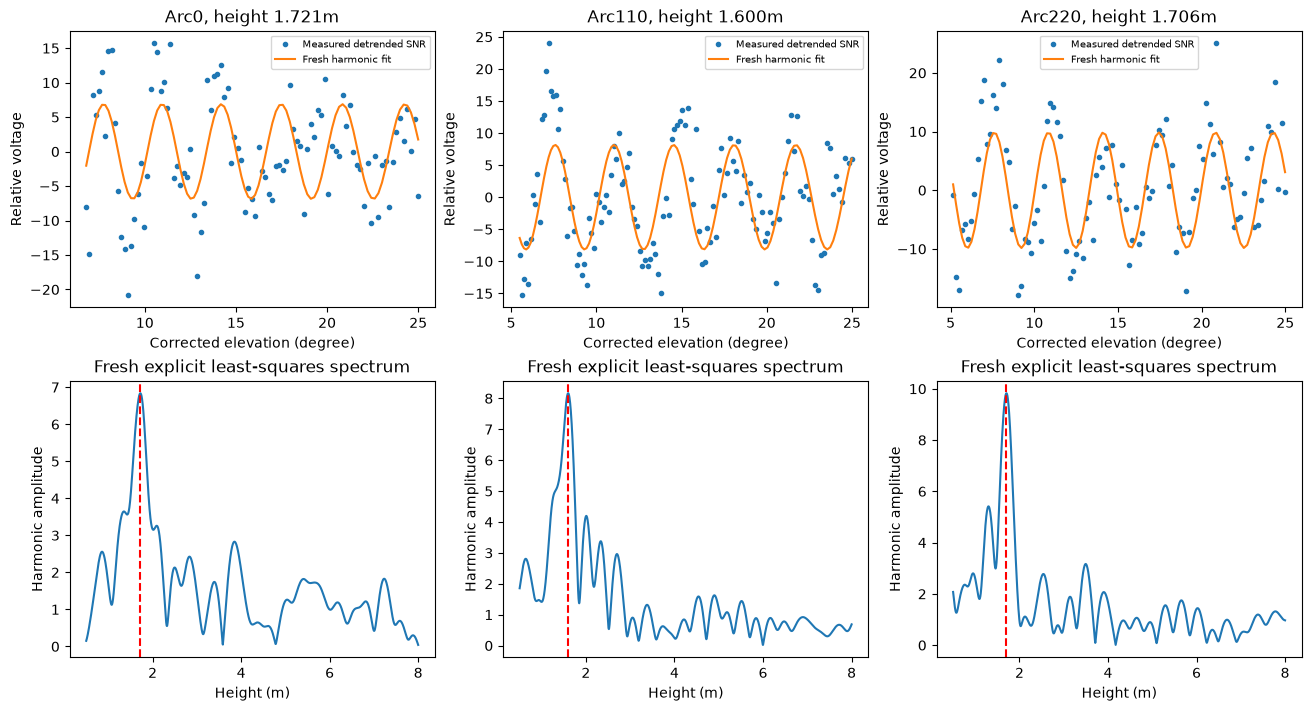

In [2]:
tick=time.perf_counter();result=reconstruct(data)
print('Fresh complete reconstruction seconds',time.perf_counter()-tick)
print('Maximum original-local error (m)',np.max(abs(result-reference['reconstruction'])))
examples(data,result);plt.show()

## Results
Each plotted measured arc and spectrum is computed from the bound observations. Fitted oscillations expose model mismatch rather than hiding it with smoothing. Numerical agreement validates extraction; the forward residual, footprint changes and grid sensitivity limit physical interpretation.

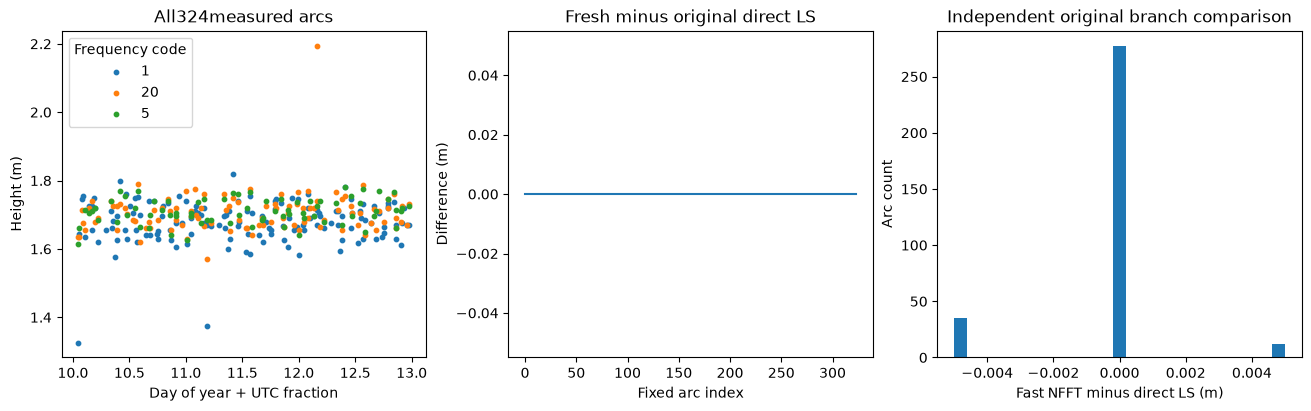

In [3]:
summary(data,result,reference['reconstruction'],reference['fast_reconstruction']);plt.show()

### Fresh sensitivity studies
The same real observations are reconstructed on coarser/finer height grids and after sample thinning. These comparisons assess numerical sensitivity; they do not create additional measured acquisitions or uncertainty intervals.

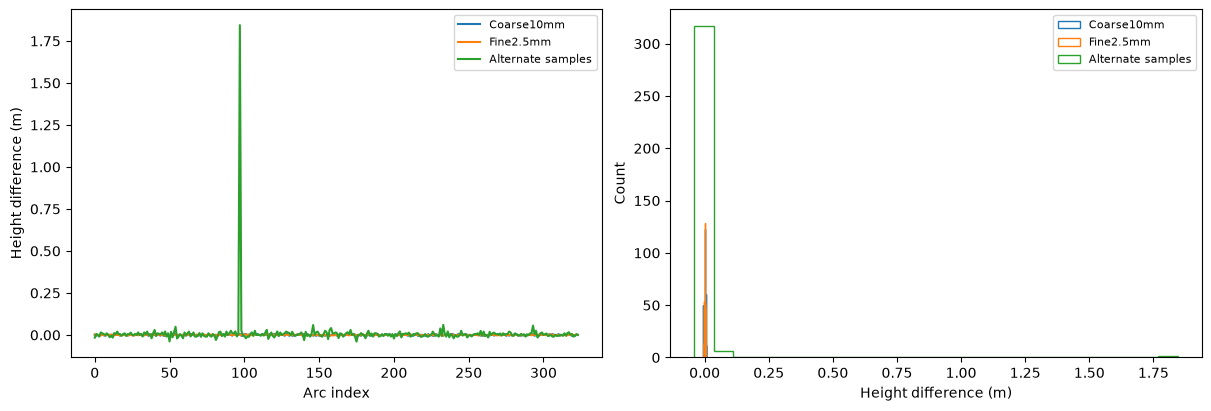

In [4]:
variants={}
for label,kwargs in [('Coarse10mm',dict(precision=.01)),('Fine2.5mm',dict(precision=.0025)),('Alternate samples',dict(stride=2))]:
    variants[label]=reconstruct(data,**kwargs)
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for label,a in variants.items():
    axs[0].plot((a-result)[0],label=label)
    axs[1].hist((a-result).ravel(),bins=25,histtype='step',label=label)
axs[0].set(xlabel='Arc index',ylabel='Height difference (m)');axs[1].set(xlabel='Height difference (m)',ylabel='Count')
for ax in axs:ax.legend(fontsize=8)
plt.show()

### Complete-acquisition residual analysis
Harmonic forward residuals below use freshly fitted linear nuisance coefficients at each reconstructed height. Large residuals are retained: a strong spectral peak does not imply a noise-free single-reflector model. The sample-thinning experiment includes a large alias switch on one arc, exposing instability rather than hiding it as an excluded result.

Frequency code 1 arc count 142 height mean/std (m) 1.6792367880625425 0.0617218706261162 median relative forward residual 0.7129765596467417
Frequency code 20 arc count 106 height mean/std (m) 1.7064624707771505 0.06242606712507886 median relative forward residual 0.5969389316424945
Frequency code 5 arc count 76 height mean/std (m) 1.7101725841512414 0.036920778609416366 median relative forward residual 0.5284224254456655


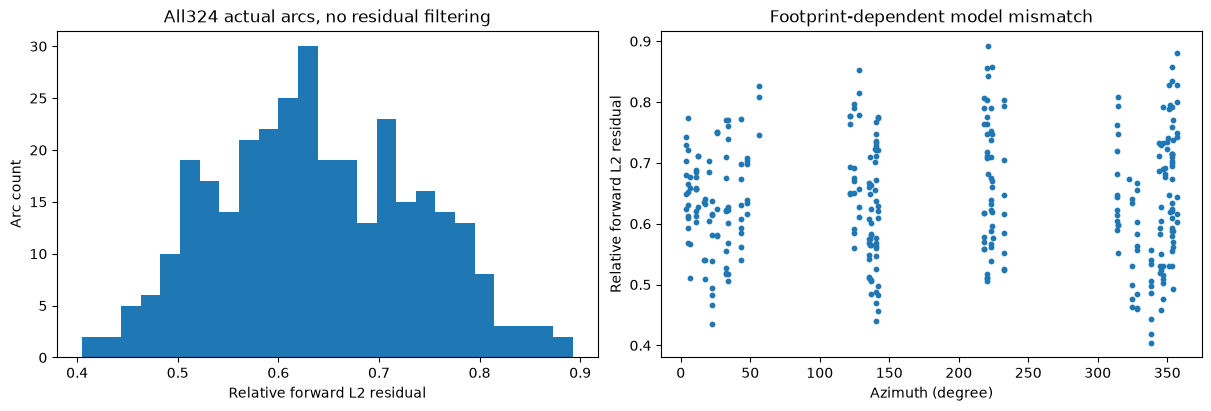

In [5]:
offset=0;relative=[]
for i,count in enumerate(data['counts']):
    e=data['elevation'][offset:offset+count];y=data['signal'][offset:offset+count];offset+=count
    x=np.sin(np.deg2rad(e))/data['half_wavelength'][i];h=result[0,i]
    design=np.column_stack((np.cos(2*np.pi*h*x),np.sin(2*np.pi*h*x)))
    coefficients=np.linalg.lstsq(design,y,rcond=None)[0]
    relative.append(np.linalg.norm(design@coefficients-y)/np.linalg.norm(y))
relative=np.array(relative)
for frequency in [1,20,5]:
    selected=data['arc_metadata'][:,2]==frequency
    print('Frequency code',frequency,'arc count',selected.sum(),'height mean/std (m)',result[0,selected].mean(),result[0,selected].std(),'median relative forward residual',np.median(relative[selected]))
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axs[0].hist(relative,bins=25);axs[0].set(xlabel='Relative forward L2 residual',ylabel='Arc count',title='All324 actual arcs, no residual filtering')
axs[1].scatter(data['arc_metadata'][:,3],relative,s=10);axs[1].set(xlabel='Azimuth (degree)',ylabel='Relative forward L2 residual',title='Footprint-dependent model mismatch')
plt.show()

## Conclusion
A fully local harmonic inverse reproduces the author-supported direct estimate on all324 measured arcs. Original fast/direct differences and fresh grid/thinning studies reveal numerical choices. Heights remain conditional on processed SNR, locally horizontal reflection and receiver calibration. Numerical parity is not true terrain accuracy; no independent physical GT or calibrated noise covariance is available.